<a href="https://colab.research.google.com/github/julienessan/Gomycode_Cours_Data_Sciences/blob/main/Checkpoint_Modifier_un_modele_pre_entra%C3%AEne.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Checkpoint: Modifier un modèle pré-entraîné

**Objectif** :

Utiliser un modèle pré-entraîné, comme VGG16, et appliquer le transfer learning pour l’adapter à une nouvelle tâche de classification d’images.

## 1. Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflow_datasets as tfds
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input

keras.utils.set_random_seed(42)

## 2. Jeu de données : Cats vs Dogs

Le jeu contient environ 23 000 photos de chats et de chiens de tailles variées. Pour que l'entraînement reste raisonnable, je n'en utilise qu'une partie :
- **entraînement** : les premiers 40 % (environ 9 300 images) ;
- **validation** : les 10 % suivants (environ 2 300 images).

Classes : 0 = chat, 1 = chien.

In [3]:
!pip install -q importlib_resources

(ds_train, ds_val), info = tfds.load(
    "cats_vs_dogs",
    split=["train[:40%]", "train[40%:50%]"],
    as_supervised=True,
    with_info=True,
)
noms = info.features["label"].names
print("Classes :", noms)
print("Images d'entraînement :", ds_train.cardinality().numpy())
print("Images de validation  :", ds_val.cardinality().numpy())

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/cats_vs_dogs/incomplete.HBRPOI_4.0.1/cats_vs_dogs-train.tfrecord-[0-9][0-9…

Dataset cats_vs_dogs downloaded and prepared to /root/tensorflow_datasets/cats_vs_dogs/4.0.1. Subsequent calls will reuse this data.
Classes : ['cat', 'dog']
Images d'entraînement : 9305
Images de validation  : 2326


### Prétraitement

Deux étapes pour chaque image :
- **redimensionnement en 160×160**, car les photos ont toutes des tailles différentes et le modèle attend une taille fixe ;
- **`preprocess_input` de VGG16** : il faut préparer les images exactement comme pendant l'entraînement de VGG16 sur ImageNet. Les canaux passent de RGB à BGR et on soustrait la couleur moyenne d'ImageNet. Il ne faut **pas** diviser par 255 ici, contrairement aux exercices précédents.

In [4]:
TAILLE = 160
BATCH = 32

def preparer(image, label):
    image = tf.image.resize(image, (TAILLE, TAILLE))
    image = preprocess_input(image)
    return image, label

ds_train = ds_train.map(preparer).shuffle(1000).batch(BATCH).prefetch(tf.data.AUTOTUNE)
ds_val = ds_val.map(preparer).batch(BATCH).prefetch(tf.data.AUTOTUNE)

Quelques exemples :

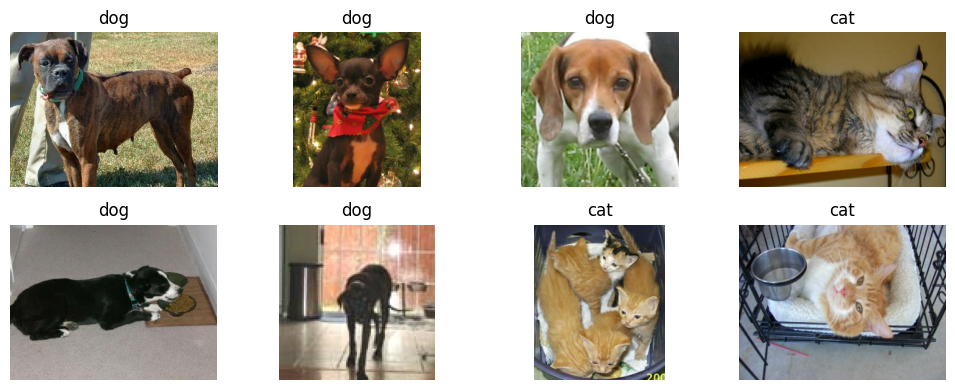

In [5]:
plt.figure(figsize=(10, 4))
for i, (image, label) in enumerate(tfds.load("cats_vs_dogs", split="train[:8]", as_supervised=True)):
    plt.subplot(2, 4, i + 1)
    plt.imshow(image)
    plt.title(noms[label])
    plt.axis("off")
plt.tight_layout()
plt.show()

## 3. Chargement de VGG16 pré-entraîné

- `weights="imagenet"` : on récupère les poids appris sur ImageNet.
- `include_top=False` : on retire les 3 couches denses finales, qui classent en 1 000 catégories ImageNet. On garde seulement les 5 blocs convolutionnels, qui servent d'**extracteur de caractéristiques**.
- `base.trainable = False` : on **gèle** toute la base. Ses 14,7 millions de poids ne seront pas modifiés pendant la phase 1.

In [6]:
base = VGG16(weights="imagenet", include_top=False, input_shape=(TAILLE, TAILLE, 3))
base.trainable = False

base.summary()

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step


Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 160, 160, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 160, 160, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 80, 80, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 80, 80, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 80, 80, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 40, 40, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 40, 40, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 40, 40, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 40, 40, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 20, 20, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 20, 20, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 20, 20, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 20, 20, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 10, 10, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 10, 10, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 10, 10, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 10, 10, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 5, 5, 512)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 14,714,688 (56.13 MB)

## 4. Ajouter la tête de classification

En suivant l'énoncé : **Flatten → Dense → Dropout → Softmax**.
- `Flatten` aplatit le 5×5×512 en un vecteur de 12 800 valeurs ;
- `Dense(256, relu)` combine ces caractéristiques ;
- `Dropout(0.5)` limite le surapprentissage, car la tête a beaucoup de paramètres;
- `Dense(2, softmax)` : **2 neurones**, un par classe (chat et chien).

L'argument `training=False` maintient la base en mode inférence.

In [7]:
entree = keras.Input(shape=(TAILLE, TAILLE, 3))
x = base(entree, training=False)
x = layers.Flatten()(x)
x = layers.Dense(256, activation="relu")(x)
x = layers.Dropout(0.5)(x)
sortie = layers.Dense(2, activation="softmax")(x)

model = keras.Model(entree, sortie)
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 5, 5, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 12800)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     3,277,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           514 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,992,258 (68.64 MB)

 Trainable params: 3,277,570 (12.50 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

## 5. Phase 1 : entraîner uniquement la tête

La base est gelée. On utilise Adam avec un taux de 0,001.

In [8]:
EPOQUES_PHASE1 = 5

model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

hist1 = model.fit(ds_train, validation_data=ds_val, epochs=EPOQUES_PHASE1)

Epoch 1/5
291/291 ━━━━━━━━━━━━━━━━━━━━ 44s 117ms/step - accuracy: 0.9385 - loss: 1.3242 - val_accuracy: 0.9652 - val_loss: 0.1111
Epoch 2/5
291/291 ━━━━━━━━━━━━━━━━━━━━ 29s 95ms/step - accuracy: 0.9675 - loss: 0.1274 - val_accuracy: 0.9695 - val_loss: 0.0945
Epoch 3/5
291/291 ━━━━━━━━━━━━━━━━━━━━ 31s 101ms/step - accuracy: 0.9730 - loss: 0.0903 - val_accuracy: 0.9690 - val_loss: 0.0937
Epoch 4/5
291/291 ━━━━━━━━━━━━━━━━━━━━ 38s 124ms/step - accuracy: 0.9751 - loss: 0.0961 - val_accuracy: 0.9746 - val_loss: 0.0826
Epoch 5/5
291/291 ━━━━━━━━━━━━━━━━━━━━ 33s 107ms/step - accuracy: 0.9795 - loss: 0.0736 - val_accuracy: 0.9746 - val_loss: 0.0902


## 6. Phase 2 : affiner le dernier bloc de VGG16

VGG16 a 5 blocs convolutionnels :
- les **premiers blocs** détectent des motifs généraux (bords, couleurs, textures), utiles pour n'importe quelle image : on les laisse **gelés** ;
- le **bloc 5** détecte des formes plus complexes, propres à ImageNet : on le **débloque** pour qu'il s'adapte aux chats et aux chiens.

In [9]:
base.trainable = True
for couche in base.layers:
    couche.trainable = couche.name.startswith("block5")

print("Couches entraînables de VGG16 :", [c.name for c in base.layers if c.trainable])

model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-5),
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])
model.summary()

Couches entraînables de VGG16 : ['block5_conv1', 'block5_conv2', 'block5_conv3', 'block5_pool']


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 5, 5, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 12800)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     3,277,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           514 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,992,258 (68.64 MB)

 Trainable params: 10,356,994 (39.51 MB)

 Non-trainable params: 7,635,264 (29.13 MB)

In [10]:
EPOQUES_PHASE2 = 5

hist2 = model.fit(ds_train, validation_data=ds_val,
                  epochs=EPOQUES_PHASE1 + EPOQUES_PHASE2,
                  initial_epoch=EPOQUES_PHASE1)

Epoch 6/10
291/291 ━━━━━━━━━━━━━━━━━━━━ 53s 155ms/step - accuracy: 0.9848 - loss: 0.0413 - val_accuracy: 0.9781 - val_loss: 0.0789
Epoch 7/10
291/291 ━━━━━━━━━━━━━━━━━━━━ 69s 126ms/step - accuracy: 0.9910 - loss: 0.0337 - val_accuracy: 0.9772 - val_loss: 0.0882
Epoch 8/10
291/291 ━━━━━━━━━━━━━━━━━━━━ 37s 122ms/step - accuracy: 0.9927 - loss: 0.0254 - val_accuracy: 0.9746 - val_loss: 0.0863
Epoch 9/10
291/291 ━━━━━━━━━━━━━━━━━━━━ 37s 122ms/step - accuracy: 0.9962 - loss: 0.0119 - val_accuracy: 0.9785 - val_loss: 0.1047
Epoch 10/10
291/291 ━━━━━━━━━━━━━━━━━━━━ 38s 124ms/step - accuracy: 0.9961 - loss: 0.0128 - val_accuracy: 0.9768 - val_loss: 0.1106


## 7. Courbes de précision et de perte

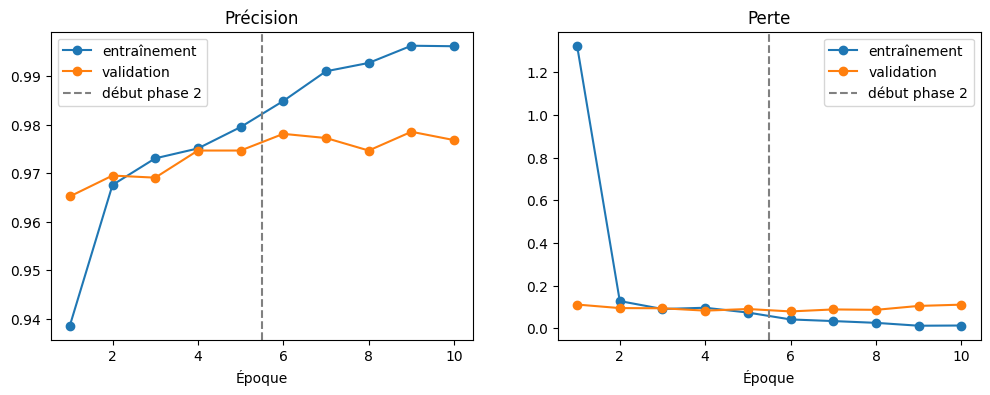

Fin phase 1 : précision val = 97.46%
Fin phase 2 : précision val = 97.68%


In [11]:
def concat(cle):
    return hist1.history[cle] + hist2.history[cle]

ep = range(1, EPOQUES_PHASE1 + EPOQUES_PHASE2 + 1)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ep, concat("accuracy"), "o-", label="entraînement")
ax[0].plot(ep, concat("val_accuracy"), "o-", label="validation")
ax[0].set_title("Précision")

ax[1].plot(ep, concat("loss"), "o-", label="entraînement")
ax[1].plot(ep, concat("val_loss"), "o-", label="validation")
ax[1].set_title("Perte")

for a in ax:
    a.axvline(EPOQUES_PHASE1 + 0.5, color="gray", linestyle="--", label="début phase 2")
    a.set_xlabel("Époque")
    a.legend()
plt.show()

print(f"Fin phase 1 : précision val = {hist1.history['val_accuracy'][-1]:.2%}")
print(f"Fin phase 2 : précision val = {hist2.history['val_accuracy'][-1]:.2%}")

## 8. Réflexion

Le transfer learning a donné d’excellents résultats dès le départ : avec seulement la tête entraînée, le modèle atteint 96,5 % de précision en validation après une seule époque et 97,5 % à la fin de la phase 1.
Le principal défi a été le prétraitement : il faut utiliser preprocess_input de VGG16 au lieu de diviser par 255, sinon les poids pré-entraînés reçoivent des images qu’ils ne savent pas interpréter.
Je retiens qu’il faut garder gelés les premiers blocs, qui détectent des motifs généraux, entraîner d’abord la tête seule, puis ne débloquer que les derniers blocs avec un taux d’apprentissage très faible, peu d’époques et un EarlyStopping sur la perte de validation, surtout quand le jeu de données est petit.